In [2]:
import pandas as pd

# قراءة الملف بالاسم الجديد والمختصر
df = pd.read_excel('data.xlsx', sheet_name='public finance', skiprows=2)

# تنظيم أسماء الأعمدة لتسهيل التعامل معها
df.columns = ['السنة', 'الإيرادات', 'إيرادات نفطية', 'إيرادات غير نفطية', 'النفقات', 'نفقات تشغيلية', 'نفقات رأسمالية', 'فائض/عجز الميزانية']

# تنظيف البيانات وحذف الصفوف الفارغة
df = df[pd.to_numeric(df['السنة'], errors='coerce').notnull()]

# عرض أول 5 صفوف للتأكد من نجاح القراءة
print(df.head())

   السنة  الإيرادات  إيرادات نفطية  إيرادات غير نفطية  النفقات  نفقات تشغيلية  \
0   1993   141445.0       105976.0            35469.0   187890         184878   
1   1994   128991.0        95505.0            33486.0   163776         161380   
2   1995   146500.0       105728.0            40772.0   173943         148776   
3   1996   179085.0       135982.0            43103.0   198117         171258   
4   1997   205500.0       159985.0            45515.0   221272         218880   

   نفقات رأسمالية  فائض/عجز الميزانية  
0            3012            -46445.0  
1            2396            -34785.0  
2           25167            -27443.0  
3           26859            -19032.0  
4            2392            -15772.0  


Matplotlib is building the font cache; this may take a moment.


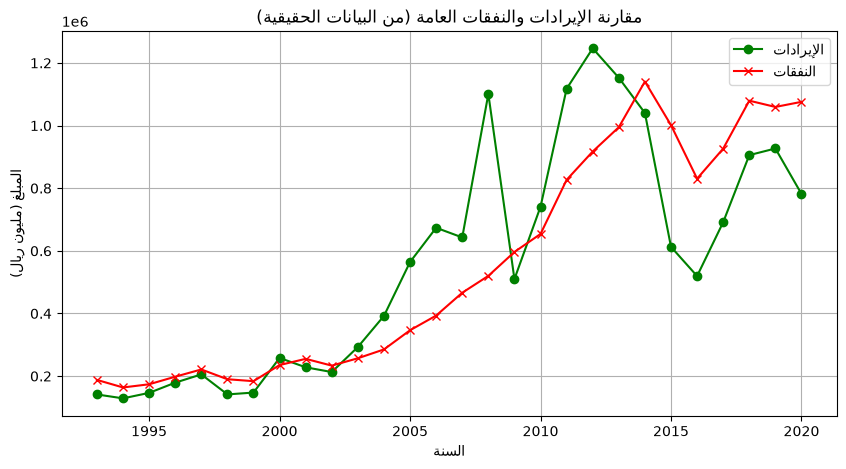

In [3]:
import matplotlib.pyplot as plt

# إعداد الرسم البياني
plt.figure(figsize=(10, 5))
plt.plot(df['السنة'], df['الإيرادات'], label='الإيرادات', marker='o', color='green')
plt.plot(df['السنة'], df['النفقات'], label='النفقات', marker='x', color='red')

plt.title('مقارنة الإيرادات والنفقات العامة (من البيانات الحقيقية)')
plt.xlabel('السنة')
plt.ylabel('المبلغ (مليون ريال)')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
from sklearn.linear_model import LinearRegression
import numpy as np

# تجهيز البيانات للنموذج التنبؤي
X = df[['السنة']].values
y = df['الإيرادات'].values

# تدريب نموذج الانحدار الخطي البسيط
model = LinearRegression()
model.fit(X, y)

# توقع الإيرادات للسنوات القادمة
future_years = np.array([[2021], [2022], [2023], [2024], [2025]])
predictions = model.predict(future_years)

print("--- توقعات الإيرادات للسنوات القادمة ---")
for yr, pred in zip(future_years, predictions):
    print(f"سنة {yr[0]}: {pred:,.2f} مليون ريال")

--- توقعات الإيرادات للسنوات القادمة ---
سنة 2021: 1,073,078.55 مليون ريال
سنة 2022: 1,108,408.26 مليون ريال
سنة 2023: 1,143,737.97 مليون ريال
سنة 2024: 1,179,067.68 مليون ريال
سنة 2025: 1,214,397.39 مليون ريال


In [6]:
import sqlite3

# إنشاء قاعدة بيانات محلية مؤقتة
conn = sqlite3.connect('saudi_budget.db')
cursor = conn.cursor()

# حفظ جدول بايثون داخل قاعدة بيانات SQL
df.to_sql('public_finances_sql', conn, if_exists='replace', index=False)

# تنفيذ استعلام SQL احترافي لاستخراج السنوات التي تجاوزت إيراداتها مليون ريال
query = """
SELECT السنة, الإيرادات, النفقات, [فائض/عجز الميزانية] 
FROM public_finances_sql 
WHERE الإيرادات > 1000000 
ORDER BY السنة DESC;
"""

result_df = pd.read_sql(query, conn)
print(result_df)

# إغلاق الاتصال
conn.close()

   السنة  الإيرادات  النفقات  فائض/عجز الميزانية
0   2014  1040141.0  1140603           -100462.0
1   2013  1152612.0   994734            157878.0
2   2012  1246538.0   917198            329340.0
3   2011  1117527.0   826700            290827.0
4   2008  1100993.0   520069            580924.0
